In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
R_df = pd.read_csv('../Dataset/Data_Engineered.csv')
df=R_df.copy()

df['date'] = pd.to_datetime(df['date'])

In [16]:
daily_total = df.groupby('date')['sales'].sum().reset_index()

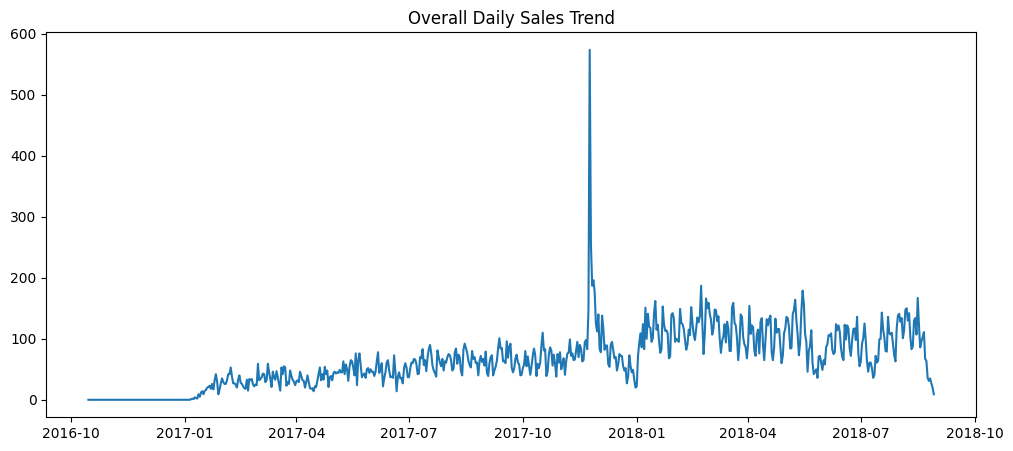

In [17]:
plt.figure(figsize=(12,5))
plt.plot(daily_total['date'], daily_total['sales'])
plt.title('Overall Daily Sales Trend')
plt.show()

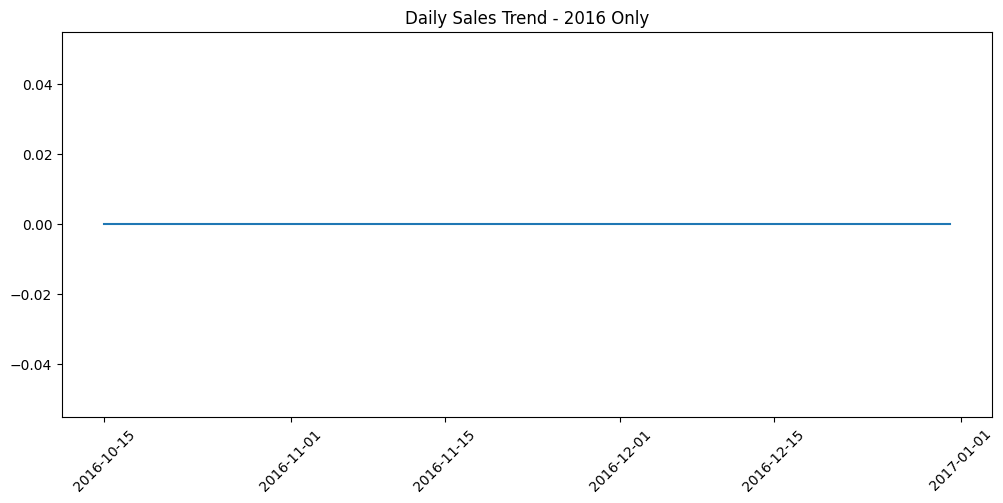

In [21]:
sales_2016 = daily_total[daily_total['date'].dt.year == 2016]

plt.figure(figsize=(12,5))
plt.plot(sales_2016['date'], sales_2016['sales'])
plt.title('Daily Sales Trend - 2016 Only')
plt.xticks(rotation=45) # Rotates dates so they don't overlap
plt.show()

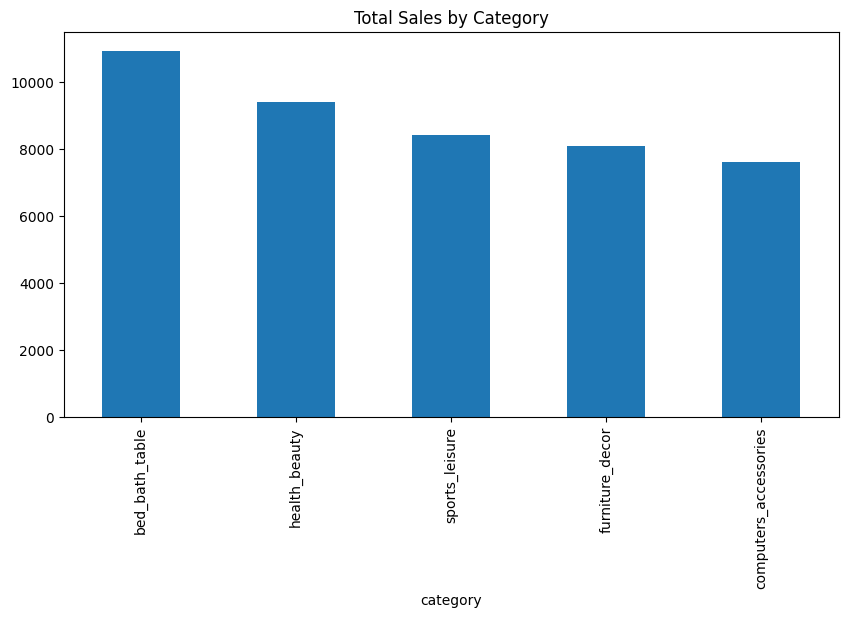

In [7]:
category_sales = df.groupby('category')['sales'].sum().sort_values(ascending=False)

category_sales.plot(kind='bar', figsize=(10,5))
plt.title('Total Sales by Category')
plt.show()

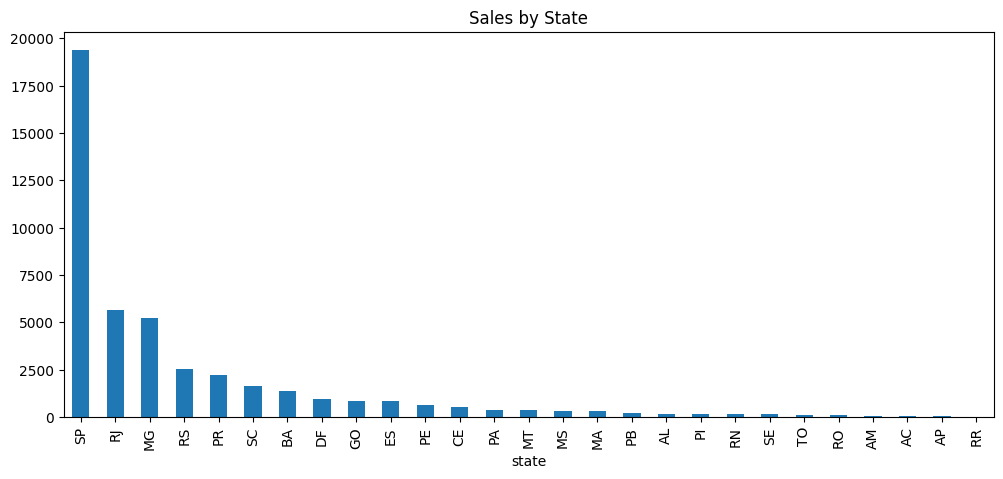

In [8]:
state_sales = df.groupby('state')['sales'].sum().sort_values(ascending=False)

state_sales.plot(kind='bar', figsize=(12,5))
plt.title('Sales by State')
plt.show()

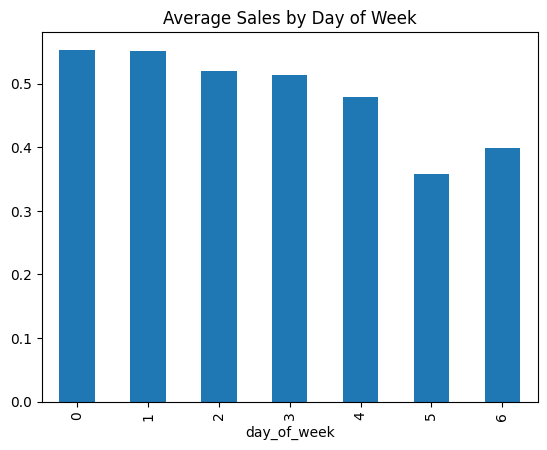

In [9]:
dow_sales = df.groupby('day_of_week')['sales'].mean()

dow_sales.plot(kind='bar')
plt.title('Average Sales by Day of Week')
plt.show()

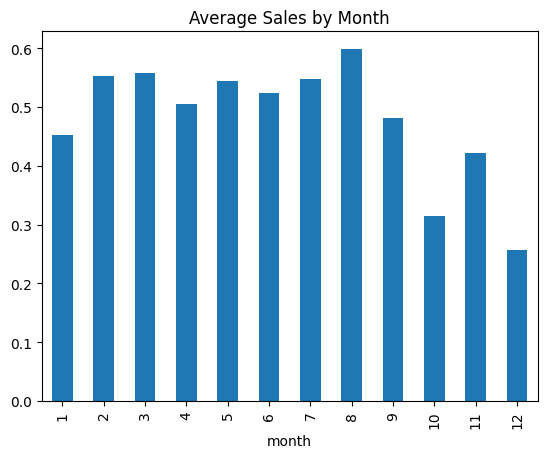

In [10]:
monthly_sales = df.groupby('month')['sales'].mean()

monthly_sales.plot(kind='bar')
plt.title('Average Sales by Month')
plt.show()

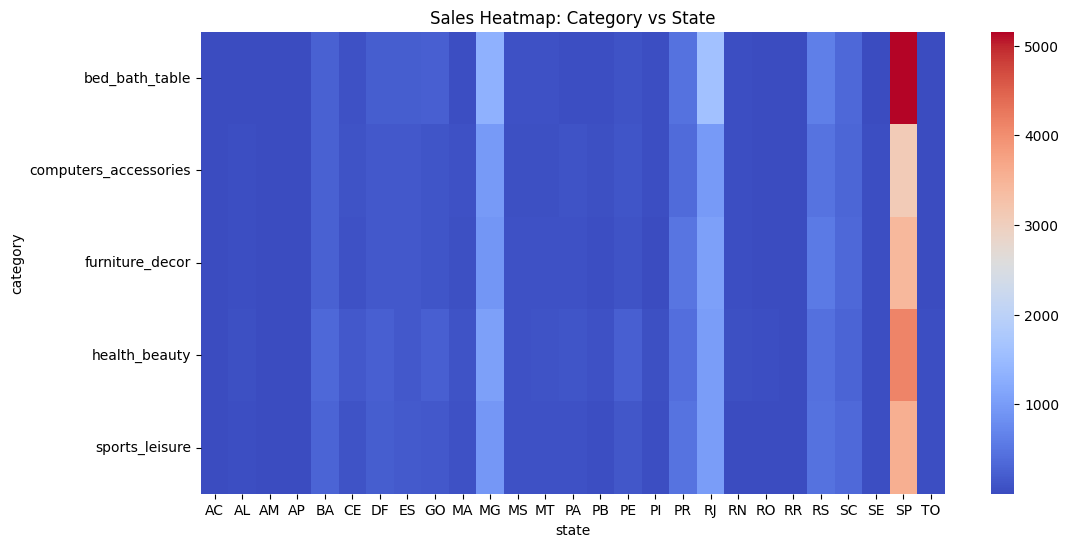

In [ ]:
pivot = df.pivot_table(
    values='sales',
    index='category',
    columns='state',
    aggfunc='sum'
)

plt.figure(figsize=(12,6))
sns.heatmap(pivot, cmap='coolwarm')
plt.title('Sales Heatmap: Category vs State')
plt.show()

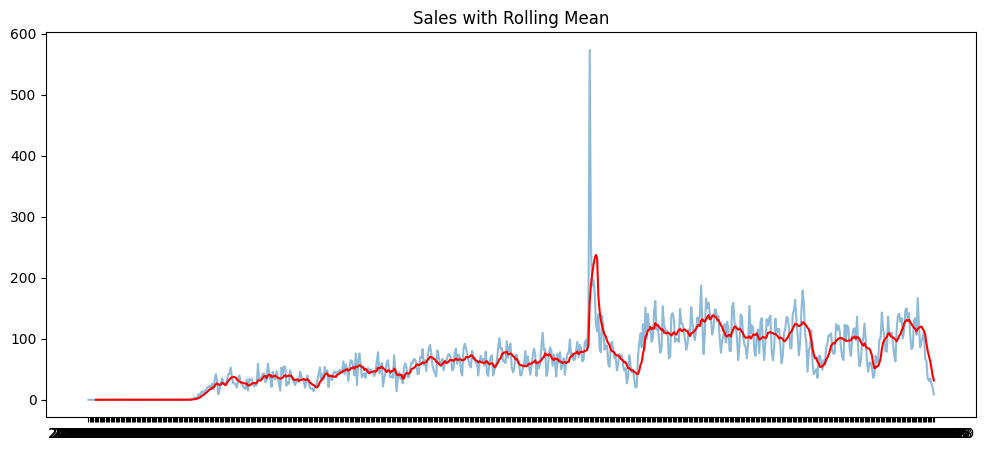

In [12]:
daily_total['rolling_mean'] = daily_total['sales'].rolling(7).mean()

plt.figure(figsize=(12,5))
plt.plot(daily_total['date'], daily_total['sales'], alpha=0.5)
plt.plot(daily_total['date'], daily_total['rolling_mean'], color='red')
plt.title('Sales with Rolling Mean')
plt.show()

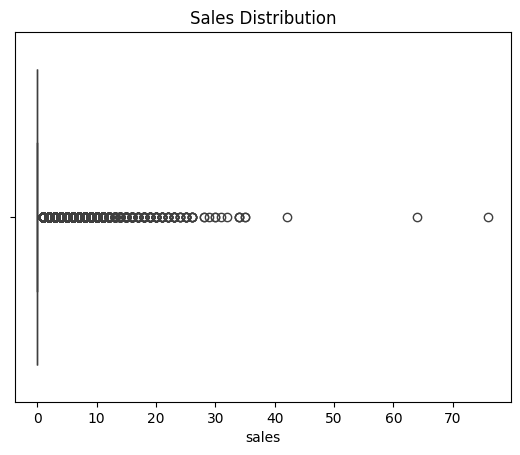

In [13]:
sns.boxplot(x=df['sales'])
plt.title('Sales Distribution')
plt.show()